### 1. Study Area: ROI Definition

The Region of Interest (ROI) is a rectangular area located around Wadi Sa'ir, in the Hebron Governorate (West Bank).

The ROI is defined using geographic coordinates (WGS84, EPSG:4326). It is intended as a preliminary study area to retrieve and inspect high-resolution orthophotos, rather than as an exact delineation of the affected agricultural parcels.

The area covers approximately 1.28 km².

In [ ]:

import geopandas as gpd
from shapely.geometry import box

# Reference point: military observation tower
tower_lat = 31.598383
tower_lon = 35.180432

# Preliminary ROI coordinates (WGS84)
# The rectangle extends mainly west of the tower
min_lon = 35.1695
min_lat = 31.5939
max_lon = 35.1830
max_lat = 31.6029

# Create ROI geometry
roi_geometry = box(
    min_lon,
    min_lat,
    max_lon,
    max_lat
)

# Store ROI in a GeoDataFrame
roi_gdf = gpd.GeoDataFrame(
    {"name": ["ROI_Wadi_Sair"]},
    geometry=[roi_geometry],
    crs="EPSG:4326"
)

# Display ROI information
print("ROI:", roi_gdf.iloc[0]["name"])
print("CRS:", roi_gdf.crs)
print("Area (km²):", roi_gdf.to_crs("EPSG:32636").area.iloc[0] / 1e6)


ROI: ROI_Wadi_Sair
CRS: EPSG:4326
Area (km²): 1.278840897721387


### 2. Access to GeoMoLG Orthophoto Services

High-resolution orthophotos are retrieved from the public ArcGIS REST services provided by the Palestinian Ministry of Local Government (GeoMoLG).

The study uses three available orthophoto services:

- 2021
- 2022
- 2023

The services are accessed through their REST endpoints. Their imagery is provided in the Palestine Grid 1923 coordinate reference system (EPSG:28191).

The 2025 service is not included because anonymous access is restricted.

In [ ]:

import requests

# GeoMoLG ArcGIS REST services
base_url = "https://orthophotos.geomolg.ps/adaptor/rest/services"

services = {
    2021: f"{base_url}/Orthophotos_WB_2021_15cm_tif_PG1923/MapServer",
    2022: f"{base_url}/Orthophotos_WB_2022_15cm_tif_PG1923_05/MapServer",
    2023: f"{base_url}/Orthophotos_WB_2023_15cm_jp2_PG1923_jp2/MapServer"
}

# Check service availability and retrieve metadata
for year, url in services.items():

    response = requests.get(
        url,
        params={"f": "json"},
        timeout=30
    )

    response.raise_for_status()
    metadata = response.json()

    print(f"\n--- {year} ---")
    print("Service:", metadata.get("name"))
    print("Status: accessible")
    print("CRS:", metadata.get("spatialReference"))
    print("Layers:", metadata.get("layers"))


JSONDecodeError: Expecting value: line 3 column 1 (char 4)

### 3. ROI Projection and Download Preparation

The ROI is initially defined in geographic coordinates (EPSG:4326). However, the GeoMoLG orthophoto services use Palestine Grid 1923 (EPSG:28191).

The ROI must therefore be reprojected before calculating its dimensions and requesting imagery.

The projected coordinates are expressed in metres, allowing us to define export tiles and estimate the required image dimensions at the nominal spatial resolution of 0.15 m per pixel.

In [ ]:

# Reproject ROI to the coordinate system used by GeoMoLG
roi_projected = roi_gdf.to_crs("EPSG:28191")

# Get projected bounding box
xmin, ymin, xmax, ymax = roi_projected.total_bounds

# Calculate ROI dimensions in metres
width_m = xmax - xmin
height_m = ymax - ymin

# Nominal image resolution
resolution = 0.15  # metres per pixel

# Estimate required image dimensions
width_px = round(width_m / resolution)
height_px = round(height_m / resolution)

print(f"ROI width: {width_m:.2f} m")
print(f"ROI height: {height_m:.2f} m")
print(f"Estimated image width: {width_px} pixels")
print(f"Estimated image height: {height_px} pixels")


ROI width: 1281.47 m
ROI height: 998.27 m
Estimated image width: 8543 pixels
Estimated image height: 6655 pixels


### 4. ROI Subdivision into Export Tiles

The ArcGIS REST service has a maximum export size of 4096 × 4096 pixels per request.

Since the complete ROI requires approximately 10,000 × 10,000 pixels at 0.15 m spatial resolution, it cannot be retrieved in a single request.

To preserve the nominal resolution, the ROI is divided into a regular grid of 3 columns and 3 rows, resulting in 9 tiles per year.

Each tile will be downloaded separately and subsequently combined into a single georeferenced raster.

In [ ]:

# Number of tiles
n_cols = 3
n_rows = 2

# Calculate tile dimensions in metres
tile_width = width_m / n_cols
tile_height = height_m / n_rows

# Generate tile bounding boxes
tiles = []

for row in range(n_rows):
    for col in range(n_cols):

        tile_xmin = xmin + col * tile_width
        tile_xmax = xmin + (col + 1) * tile_width

        tile_ymax = ymax - row * tile_height
        tile_ymin = ymax - (row + 1) * tile_height

        tiles.append({
            "id": f"R{row+1}_C{col+1}",
            "bbox": (
                tile_xmin,
                tile_ymin,
                tile_xmax,
                tile_ymax
            )
        })

print(f"Number of tiles: {len(tiles)}")
print(f"Tile dimensions: {tile_width:.2f} × {tile_height:.2f} m")

for tile in tiles:
    print(tile["id"], tile["bbox"])


Number of tiles: 6
Tile dimensions: 427.16 × 499.13 m
R1_C1 (np.float64(166139.19238699187), np.float64(111785.46606524364), np.float64(166566.3477461016), np.float64(112284.59982433631))
R1_C2 (np.float64(166566.3477461016), np.float64(111785.46606524364), np.float64(166993.50310521133), np.float64(112284.59982433631))
R1_C3 (np.float64(166993.50310521133), np.float64(111785.46606524364), np.float64(167420.65846432105), np.float64(112284.59982433631))
R2_C1 (np.float64(166139.19238699187), np.float64(111286.33230615096), np.float64(166566.3477461016), np.float64(111785.46606524364))
R2_C2 (np.float64(166566.3477461016), np.float64(111286.33230615096), np.float64(166993.50310521133), np.float64(111785.46606524364))
R2_C3 (np.float64(166993.50310521133), np.float64(111286.33230615096), np.float64(167420.65846432105), np.float64(111785.46606524364))


### 5. Test Export: 2021 Orthophoto

Before downloading all tiles, one tile from the 2021 orthophoto service is exported to verify that the new ROI is correctly located and that the image can be retrieved at the expected spatial resolution.

The export is requested in PNG format. The service previously returned PNG images even when TIFF was requested. We will use the geographic extent returned by the server to georeference the downloaded image in a later step.

In [ ]:

import requests
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from io import BytesIO

# Select the first tile
test_tile = tiles[0]
txmin, tymin, txmax, tymax = test_tile["bbox"]

# Calculate output dimensions at 15 cm resolution
tile_width_px = round((txmax - txmin) / resolution)
tile_height_px = round((tymax - tymin) / resolution)

# GeoMoLG 2021 export endpoint
export_url = f"{services[2021]}/export"

# Export parameters
params = {
    "bbox": f"{txmin},{tymin},{txmax},{tymax}",
    "bboxSR": 28191,
    "imageSR": 28191,
    "size": f"{tile_width_px},{tile_height_px}",
    "format": "png",
    "pixelType": "U8",
    "f": "json"
}

# Request image export
response = requests.get(
    export_url,
    params=params,
    timeout=120
)

response.raise_for_status()
export_result = response.json()

# Download the generated image
image_url = export_result["href"]

image_response = requests.get(image_url, timeout=120)
image_response.raise_for_status()

test_image = Image.open(BytesIO(image_response.content))


# Convert paletted image to RGB
test_image_rgb = test_image.convert("RGB")

# Convert to NumPy array
test_array = np.array(test_image_rgb)

# Visualize image
plt.figure(figsize=(10, 10))
plt.imshow(test_array)
plt.title("GeoMoLG 2021 – Wadi Sa'ir test tile")
plt.axis("off")
plt.show()


JSONDecodeError: Expecting value: line 3 column 1 (char 4)

### 6. Downloading the 2021 and 2023 Orthophotos

The six tiles covering the Wadi Sa'ir ROI are downloaded from the GeoMoLG ArcGIS REST services for 2021 and 2023.

Both years use the same tile boundaries and nominal spatial resolution (0.15 m/pixel), allowing a spatial comparison of the area before and after the reported incident.

The images are stored temporarily in memory, together with the actual geographic extent returned by the server for each export. This extent is important because it will be used later to assign the correct georeferencing.

The PNG images are converted to RGB to ensure consistent image handling, regardless of the colour mode returned by the service.

In [ ]:

from PIL import Image
from io import BytesIO
import requests

# Years selected for comparison
years_to_download = [2021, 2023]

# Dictionaries to store images and their geographic extents
downloaded_images = {}
downloaded_extents = {}

# Download all tiles for each year
for year in years_to_download:

    print(f"\nDownloading {year} orthophotos...")

    downloaded_images[year] = {}
    downloaded_extents[year] = {}

    export_url = f"{services[year]}/export"

    for tile in tiles:

        tile_id = tile["id"]
        txmin, tymin, txmax, tymax = tile["bbox"]

        # Calculate output dimensions at 15 cm resolution
        tile_width_px = round((txmax - txmin) / resolution)
        tile_height_px = round((tymax - tymin) / resolution)

        # Export parameters
        params = {
            "bbox": f"{txmin},{tymin},{txmax},{tymax}",
            "bboxSR": 28191,
            "imageSR": 28191,
            "size": f"{tile_width_px},{tile_height_px}",
            "format": "png",
            "pixelType": "U8",
            "f": "json"
        }

        # Request export
        response = requests.get(
            export_url,
            params=params,
            timeout=120
        )
        response.raise_for_status()

        export_result = response.json()

        if "href" not in export_result:
            raise RuntimeError(
                f"Export failed for {year} {tile_id}: {export_result}"
            )

        # Download generated image
        image_response = requests.get(
            export_result["href"],
            timeout=120
        )
        image_response.raise_for_status()

        # Convert image to RGB
        image = Image.open(
            BytesIO(image_response.content)
        ).convert("RGB")

        # Store image and actual returned extent
        downloaded_images[year][tile_id] = image
        downloaded_extents[year][tile_id] = export_result["extent"]

        print(
            f"{tile_id}: {image.size[0]} × {image.size[1]} pixels"
        )

print("\nDownload completed.")

for year in years_to_download:
    print(f"{year}: {len(downloaded_images[year])} tiles")



R1_C1: 2848 × 3328 pixels
R1_C2: 2848 × 3328 pixels
R1_C3: 2848 × 3328 pixels
R2_C1: 2848 × 3328 pixels
R2_C2: 2848 × 3328 pixels
R2_C3: 2848 × 3328 pixels

R1_C1: 2848 × 3328 pixels
R1_C2: 2848 × 3328 pixels
R1_C3: 2848 × 3328 pixels
R2_C1: 2848 × 3328 pixels
R2_C2: 2848 × 3328 pixels
R2_C3: 2848 × 3328 pixels

Download completed.
2021: 6 tiles
2023: 6 tiles


### 7. Georeferencing the Orthophoto Tiles

The downloaded PNG images do not retain their geographic coordinates as raster metadata.

To make them usable in GIS software, each image is converted into a GeoTIFF using:

- The image dimensions (number of columns and rows).
- The geographic extent returned by the GeoMoLG export service.
- The coordinate reference system EPSG:28191 (Palestine Grid 1923).

The affine transformation is calculated from the returned extent and the image dimensions. This assigns a geographic location to every pixel.

Each tile is saved separately as a georeferenced GeoTIFF. The tiles will be mosaicked in a subsequent step.

In [ ]:

import os
import rasterio
import numpy as np
from rasterio.transform import from_bounds

# Output directories
output_dirs = {
    2021: "/content/orthophotos/2021",
    2023: "/content/orthophotos/2023"
}

for year in years_to_download:

    os.makedirs(output_dirs[year], exist_ok=True)

    print(f"\nGeoreferencing {year} tiles...")

    for tile_id, image in downloaded_images[year].items():

        # Get actual geographic extent returned by GeoMoLG
        extent = downloaded_extents[year][tile_id]

        xmin_img = extent["xmin"]
        ymin_img = extent["ymin"]
        xmax_img = extent["xmax"]
        ymax_img = extent["ymax"]

        # Image dimensions
        width, height = image.size

        # Calculate affine transformation
        transform = from_bounds(
            xmin_img,
            ymin_img,
            xmax_img,
            ymax_img,
            width,
            height
        )

        # Convert image to NumPy array (bands, rows, columns)
        image_array = np.array(image).transpose(2, 0, 1)

        # Output filename
        output_path = os.path.join(
            output_dirs[year],
            f"{tile_id}_{year}.tif"
        )

        # Write georeferenced GeoTIFF
        with rasterio.open(
            output_path,
            "w",
            driver="GTiff",
            width=width,
            height=height,
            count=3,
            dtype="uint8",
            crs="EPSG:28191",
            transform=transform,
            compress="lzw",
            photometric="RGB"
        ) as dst:

            dst.write(image_array)

        print(f"Saved: {output_path}")

print("\nAll GeoTIFF tiles created.")



Georeferencing 2021 tiles...
Saved: /content/orthophotos/2021/R1_C1_2021.tif
Saved: /content/orthophotos/2021/R1_C2_2021.tif
Saved: /content/orthophotos/2021/R1_C3_2021.tif
Saved: /content/orthophotos/2021/R2_C1_2021.tif
Saved: /content/orthophotos/2021/R2_C2_2021.tif
Saved: /content/orthophotos/2021/R2_C3_2021.tif

Georeferencing 2023 tiles...
Saved: /content/orthophotos/2023/R1_C1_2023.tif
Saved: /content/orthophotos/2023/R1_C2_2023.tif
Saved: /content/orthophotos/2023/R1_C3_2023.tif
Saved: /content/orthophotos/2023/R2_C1_2023.tif
Saved: /content/orthophotos/2023/R2_C2_2023.tif
Saved: /content/orthophotos/2023/R2_C3_2023.tif

All GeoTIFF tiles created.


### 8. Validation of Georeferenced Tiles

Before mosaicking, the GeoTIFF files are inspected to verify their spatial metadata.

The following properties are checked:

- Coordinate reference system (CRS).
- Raster dimensions.
- Number of bands.
- Pixel size in metres.
- Geographic bounds.

The expected pixel size is approximately 0.15 × 0.15 metres. Small differences may occur due to rounding of the output dimensions and the extent returned by the export service.

In [ ]:

import os
import rasterio

for year in years_to_download:

    print(f"\n{'='*20} {year} {'='*20}")

    for filename in sorted(os.listdir(output_dirs[year])):

        if filename.endswith(".tif"):

            filepath = os.path.join(output_dirs[year], filename)

            with rasterio.open(filepath) as src:

                print(f"\nFile: {filename}")
                print("CRS:", src.crs)
                print("Dimensions:", src.width, "×", src.height)
                print("Bands:", src.count)
                print(
                    "Pixel size:",
                    f"{abs(src.res[0]):.4f} × {abs(src.res[1]):.4f} m"
                )
                print("Bounds:", src.bounds)


NameError: name 'years_to_download' is not defined

### 9. Mosaicking the Orthophoto Tiles

The six georeferenced tiles for each year are combined into a single raster mosaic.

The mosaicking process uses the spatial metadata of each GeoTIFF to position the tiles correctly. The original RGB pixel values are preserved, without applying colour corrections or spatial resampling intentionally.

Two separate mosaics are generated:

- `Wadi_Sair_2021.tif`
- `Wadi_Sair_2023.tif`

Both mosaics will use EPSG:28191 and will cover the same study area, allowing them to be loaded and compared in QGIS.

In [ ]:

import os
import rasterio
from rasterio.merge import merge

# Output directory
mosaic_dir = "/content/orthophotos/mosaics"
os.makedirs(mosaic_dir, exist_ok=True)

for year in years_to_download:

    print(f"\nCreating {year} mosaic...")

    # Get tile file paths
    tile_paths = [
        os.path.join(output_dirs[year], filename)
        for filename in sorted(os.listdir(output_dirs[year]))
        if filename.endswith(".tif")
    ]

    # Open all tiles
    src_files = [
        rasterio.open(path) for path in tile_paths
    ]

    try:
        # Merge tiles using the original pixel resolution
        mosaic, mosaic_transform = merge(
            src_files,
            res=src_files[0].res,
            method="first"
        )

        # Update metadata
        mosaic_meta = src_files[0].meta.copy()
        mosaic_meta.update({
            "driver": "GTiff",
            "height": mosaic.shape[1],
            "width": mosaic.shape[2],
            "transform": mosaic_transform,
            "count": 3,
            "compress": "lzw"
        })

        # Save mosaic
        output_path = os.path.join(
            mosaic_dir,
            f"Wadi_Sair_{year}.tif"
        )

        with rasterio.open(output_path, "w", **mosaic_meta) as dst:
            dst.write(mosaic)

        print("Saved:", output_path)
        print("Dimensions:", mosaic.shape[2], "×", mosaic.shape[1])
        print("Bands:", mosaic.shape[0])

    finally:
        # Close source files
        for src in src_files:
            src.close()

print("\nBoth mosaics created successfully.")



Creating 2021 mosaic...
Saved: /content/orthophotos/mosaics/Wadi_Sair_2021.tif
Dimensions: 8544 × 6656
Bands: 3

Creating 2023 mosaic...
Saved: /content/orthophotos/mosaics/Wadi_Sair_2023.tif
Dimensions: 8544 × 6656
Bands: 3

Both mosaics created successfully.


### 10. Visual Inspection of the Orthophoto Mosaics

Both annual mosaics are displayed using their RGB bands.

This visual inspection allows us to check the spatial continuity between tiles, identify possible gaps or artefacts, and confirm that the study area is correctly represented.

At this stage, no image enhancement or radiometric normalization is applied. The purpose is to inspect the original orthophoto appearance.

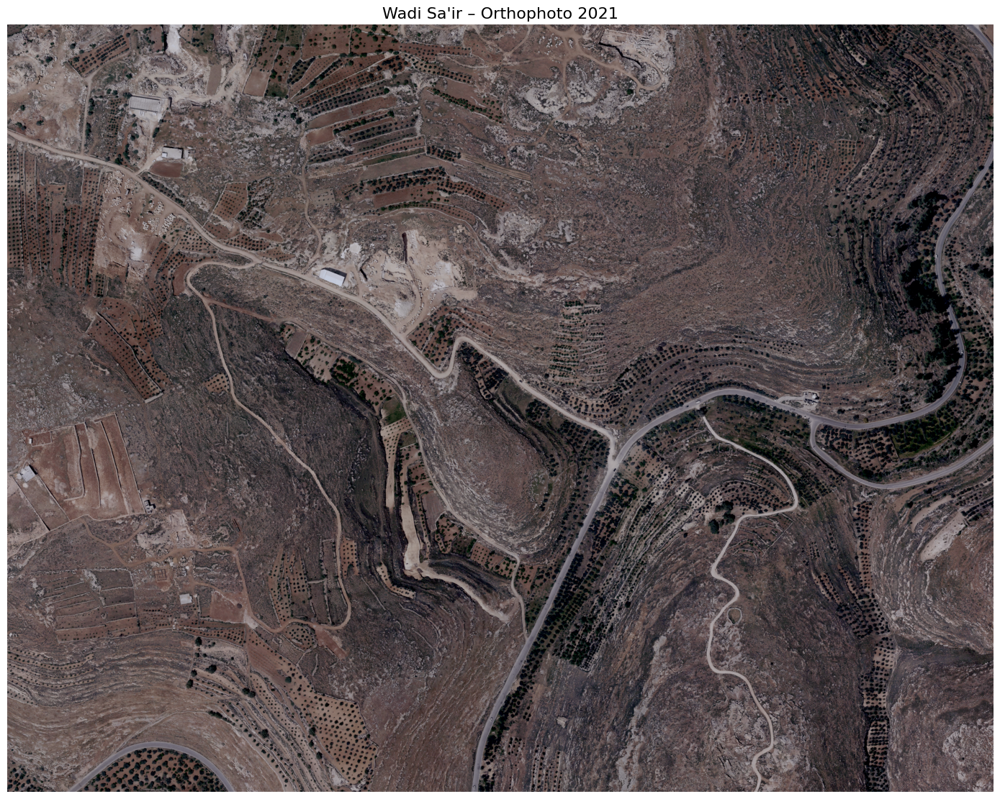

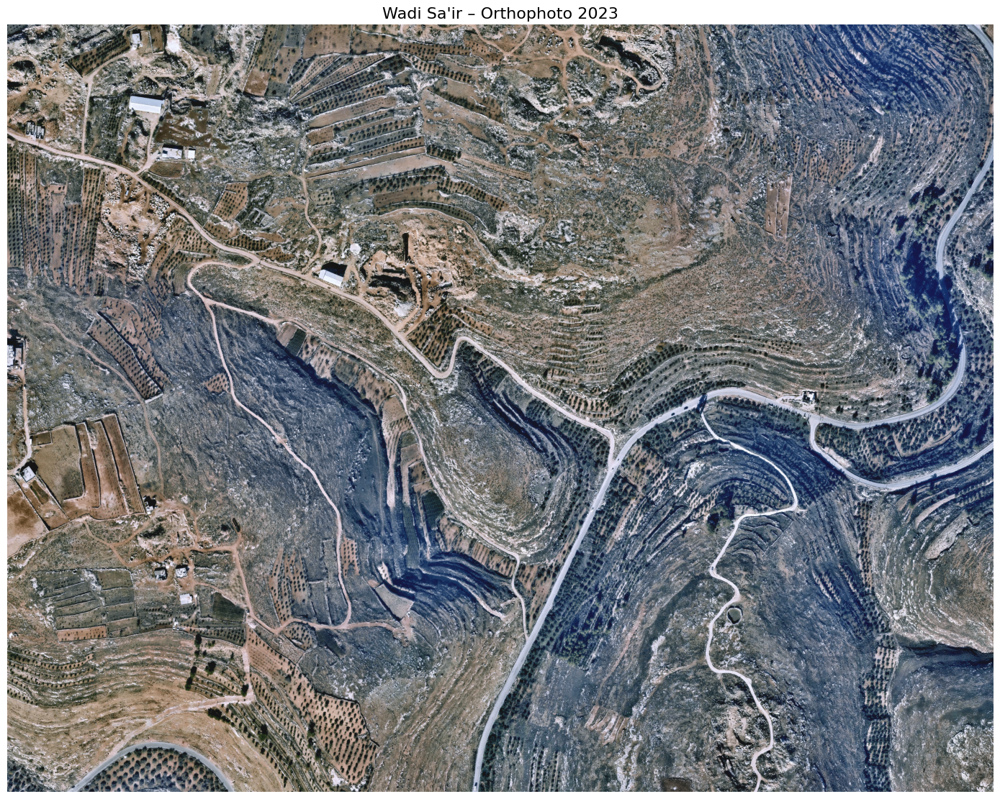

In [ ]:

import rasterio
import matplotlib.pyplot as plt
import numpy as np
import os

for year in years_to_download:

    mosaic_path = os.path.join(
        mosaic_dir,
        f"Wadi_Sair_{year}.tif"
    )

    with rasterio.open(mosaic_path) as src:
        image = src.read([1, 2, 3])
        image = np.transpose(image, (1, 2, 0))

    plt.figure(figsize=(14, 12))

    plt.imshow(image)
    plt.title(f"Wadi Sa'ir – Orthophoto {year}", fontsize=16)
    plt.axis("off")
    plt.tight_layout()
    plt.show()


In [ ]:
import shutil
from google.colab import files

# Compress the complete orthophotos directory
zip_path = shutil.make_archive(
    "/content/Wadi_Sair_orthophotos",
    "zip",
    "/content",
    "orthophotos"
)

# Download the ZIP file
files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 11. Image Segmentation and Land-Cover Classification in QGIS

Following the visual inspection of the orthophoto mosaics, the workflow is temporarily transferred from Python to QGIS for image segmentation and land-cover classification.

The RGB composites generated in the previous steps are exported and imported into QGIS, where the GeoAI tool is used to perform AI-based image segmentation. The resulting image segments are then classified using a Random Forest classifier, trained with manually selected samples from each composite. To perform this step, a smaller ROI was created around the area of interest.

This process is carried out independently for both reference and post-period composites, producing two classified rasters representing the land-cover distribution during the respective periods.

The resulting classification maps are subsequently exported and reintroduced into the Python workflow for further processing and change analysis.
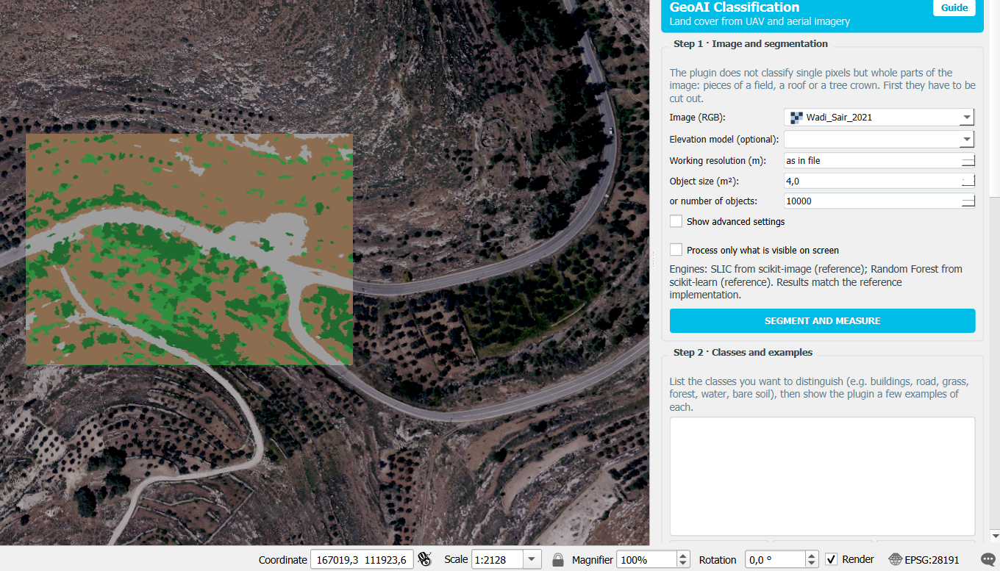

### 12. Importing the Land-Cover Classification Results

Following the segmentation and Random Forest classification performed in QGIS using the GeoAI tool, both classified rasters are imported back into the Python environment.

The two classification maps correspond to the following periods:

- **2021:** `Wadi_Sair_2021_classification.tif`
- **2023:** `Wadi_Sair_2023_classification.tif`

These rasters represent the classified land-cover segments for each period and will serve as the input datasets for the subsequent change analysis.

Both classifications are loaded into Python to enable further spatial processing and comparison of land-cover changes between 2021 and 2023.

In [9]:
from google.colab import files

uploaded = files.upload()

Saving Wadi_Sair_2021_classification.tif to Wadi_Sair_2021_classification.tif
Saving Wadi_Sair_2023_classification.tif to Wadi_Sair_2023_classification.tif


### 13. Visualisation of Land-Cover Classifications (2021 and 2023)

Both classified rasters are visualised to inspect the land-cover distribution for the two reference years (2021 and 2023).

Displaying the classification maps side by side allows for a visual comparison of the spatial patterns and distribution of the identified land-cover classes.

This step provides an initial assessment of the classification results and helps identify potential differences between the two periods before proceeding with the change analysis.

In [11]:
import rasterio

tif_path = next(iter(uploaded.keys()))

with rasterio.open(tif_path) as src:
    print("Dimensions:", src.width, "×", src.height)
    print("Number of bands:", src.count)
    print("CRS:", src.crs)
    print("Pixel size:", src.res)
    print("Data type:", src.dtypes)
    print("NoData:", src.nodata)
    print("Bounds:", src.bounds)
    print("File size (MB):", round(src.files[0] and __import__("os").path.getsize(tif_path) / 1e6, 3))

Dimensions: 1331 × 941
Number of bands: 1
CRS: EPSG:28191
Pixel size: (0.14998432553009766, 0.1499843255300955)
Data type: ('uint8',)
NoData: 0.0
Bounds: BoundingBox(left=167021.4001897599, bottom=111715.26636275984, right=167221.02932704048, top=111856.40161308365)
File size (MB): 0.058


In [12]:
import numpy as np

with rasterio.open(tif_path) as src:
    data = src.read(1)

values, counts = np.unique(data, return_counts=True)

for value, count in zip(values, counts):
    print(
        f"Value: {value} | "
        f"Pixels: {count:,} | "
        f"Percentage: {count / data.size * 100:.2f}%"
    )

Value: 1 | Pixels: 724,937 | Percentage: 57.88%
Value: 2 | Pixels: 209,784 | Percentage: 16.75%
Value: 3 | Pixels: 124,651 | Percentage: 9.95%
Value: 4 | Pixels: 193,099 | Percentage: 15.42%


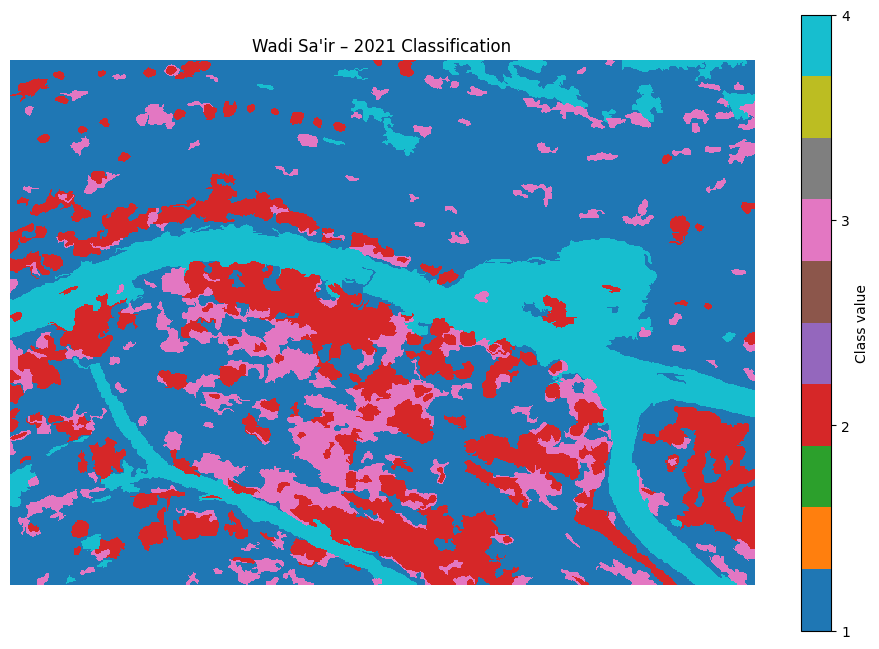

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

plt.imshow(data, cmap="tab10", interpolation="nearest")
plt.colorbar(label="Class value", ticks=[1, 2, 3, 4])

plt.title("Wadi Sa'ir – 2021 Classification")
plt.axis("off")
plt.show()

In [14]:
tif_path_2023 = next(
    name for name in uploaded.keys()
    if "2023" in name
)

with rasterio.open(tif_path_2023) as src:
    data_2023 = src.read(1)

    print("Dimensions:", src.width, "×", src.height)
    print("CRS:", src.crs)
    print("Pixel size:", src.res)
    print("Data type:", src.dtypes)

Dimensions: 1332 × 941
CRS: EPSG:28191
Pixel size: (0.14998432553009766, 0.1499843255300955)
Data type: ('uint8',)


In [15]:
values_2023, counts_2023 = np.unique(
    data_2023, return_counts=True
)

for value, count in zip(values_2023, counts_2023):
    print(
        f"Category: {value} | "
        f"Pixels: {count:,} | "
        f"Percentage: {count / data_2023.size * 100:.2f}%"
    )

Category: 1 | Pixels: 148,785 | Percentage: 11.87%
Category: 2 | Pixels: 287,491 | Percentage: 22.94%
Category: 3 | Pixels: 513,221 | Percentage: 40.95%
Category: 4 | Pixels: 303,915 | Percentage: 24.25%


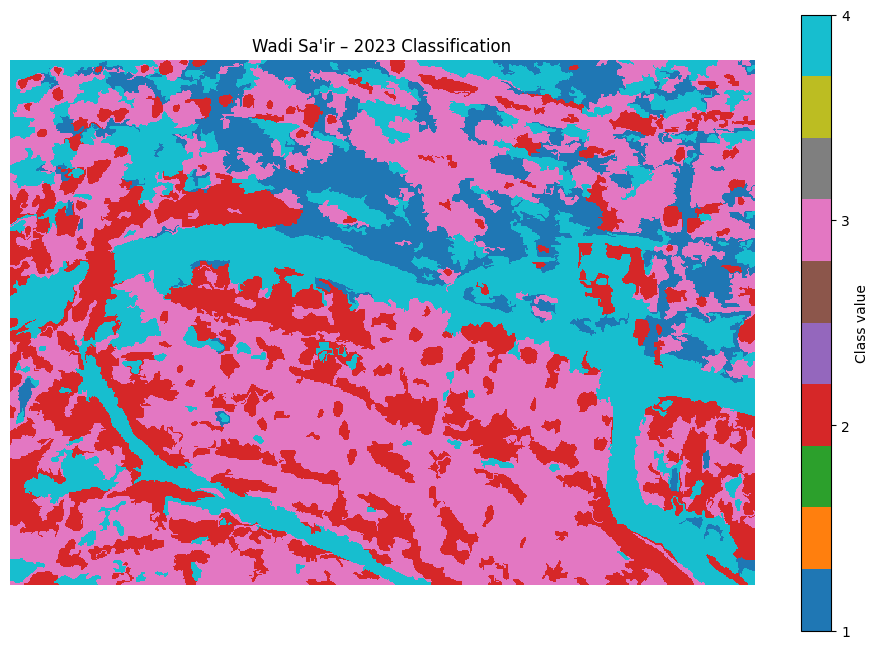

In [16]:
plt.figure(figsize=(12, 8))

plt.imshow(
    data_2023,
    cmap="tab10",
    interpolation="nearest",
    vmin=1,
    vmax=4
)

plt.colorbar(label="Class value", ticks=[1, 2, 3, 4])

plt.title("Wadi Sa'ir – 2023 Classification")
plt.axis("off")
plt.show()

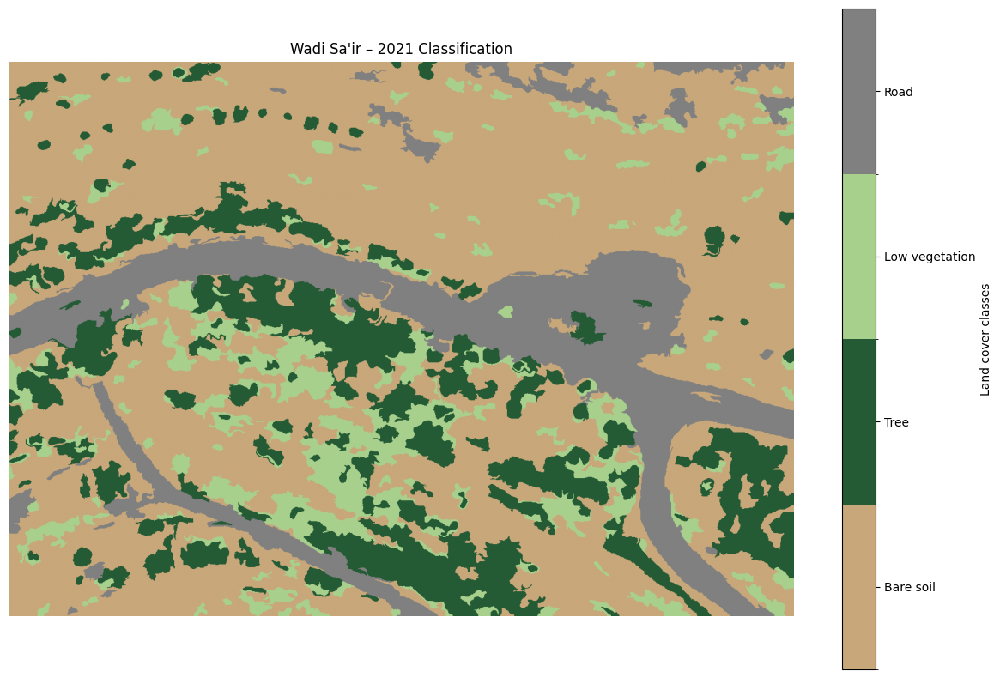

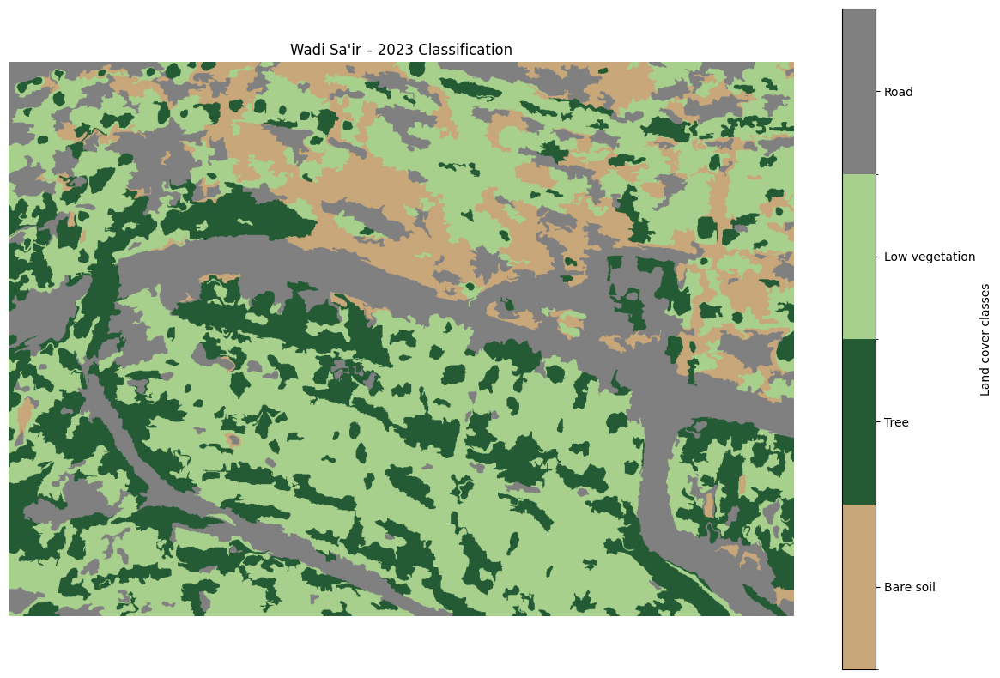

In [17]:
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.pyplot as plt

# Define the same colour palette for both years
colors = [
    "#C8A77A",  # 1 - Bare soil
    "#245B35",  # 2 - Tree
    "#A8D08D",  # 3 - Low vegetation
    "#808080"   # 4 - Road
]

class_names = [
    "Bare soil",
    "Tree",
    "Low vegetation",
    "Road"
]

cmap = ListedColormap(colors)
norm = BoundaryNorm([0.5, 1.5, 2.5, 3.5, 4.5], cmap.N)

# Plot 2021
for year, image in [(2021, data), (2023, data_2023)]:

    fig, ax = plt.subplots(figsize=(12, 8))

    im = ax.imshow(image, cmap=cmap, norm=norm)

    cbar = fig.colorbar(
        im,
        ax=ax,
        ticks=[1, 2, 3, 4],
        boundaries=[0.5, 1.5, 2.5, 3.5, 4.5]
    )

    cbar.ax.set_yticklabels(class_names)
    cbar.set_label("Land cover classes")

    ax.set_title(f"Wadi Sa'ir – {year} Classification")
    ax.axis("off")

    plt.tight_layout()
    plt.show()

### 14. Pixel-Based Tree Cover Change Detection (2021–2023)

The two classified rasters are compared on a pixel-by-pixel basis to identify changes in the **Tree** class between 2021 and 2023.

The analysis focuses exclusively on the Tree category, identifying pixels where tree cover is gained or lost between the two periods. Changes in the remaining land-cover categories are not considered.

A new difference raster is generated to represent the spatial distribution of tree cover changes across the study area, distinguishing between tree gain, tree loss and areas with no change in tree cover.

In [18]:
import rasterio
import numpy as np
from rasterio.windows import from_bounds
from rasterio.warp import reproject, Resampling

with rasterio.open(tif_path) as src_2021, \
     rasterio.open(tif_path_2023) as src_2023:

    # Check CRS
    if src_2021.crs != src_2023.crs:
        raise ValueError("The rasters have different CRS.")

    # Calculate common spatial extent
    bounds_2021 = src_2021.bounds
    bounds_2023 = src_2023.bounds

    common_left = max(bounds_2021.left, bounds_2023.left)
    common_bottom = max(bounds_2021.bottom, bounds_2023.bottom)
    common_right = min(bounds_2021.right, bounds_2023.right)
    common_top = min(bounds_2021.top, bounds_2023.top)

    if common_left >= common_right or common_bottom >= common_top:
        raise ValueError("The rasters do not overlap.")

    # Crop 2021 to the common extent
    window_2021 = from_bounds(
        common_left, common_bottom,
        common_right, common_top,
        src_2021.transform
    ).round_offsets().round_lengths()

    data_2021_common = src_2021.read(1, window=window_2021)
    transform_common = src_2021.window_transform(window_2021)

    # Create an empty array on the 2021 grid for 2023
    data_2023_common = np.zeros(
        data_2021_common.shape,
        dtype=np.uint8
    )

    # Reproject 2023 onto the cropped 2021 grid
    reproject(
        source=rasterio.band(src_2023, 1),
        destination=data_2023_common,
        src_transform=src_2023.transform,
        src_crs=src_2023.crs,
        dst_transform=transform_common,
        dst_crs=src_2021.crs,
        resampling=Resampling.nearest,
        src_nodata=0,
        dst_nodata=0
    )

print("Common area dimensions:", data_2021_common.shape)
print("2021 pixels:", data_2021_common.size)
print("2023 pixels:", data_2023_common.size)
print("Pixel size:", src_2021.res)

Common area dimensions: (940, 1330)
2021 pixels: 1250200
2023 pixels: 1250200
Pixel size: (0.14998432553009766, 0.1499843255300955)


In [19]:
print("2021 unique values:", np.unique(data_2021_common, return_counts=True))
print("2023 unique values:", np.unique(data_2023_common, return_counts=True))

valid_pixels = (
    (data_2021_common != 0) &
    (data_2023_common != 0)
)

print("\nValid pixels:", np.count_nonzero(valid_pixels))
print("Excluded pixels:", np.count_nonzero(~valid_pixels))

2021 unique values: (array([1, 2, 3, 4], dtype=uint8), array([723380, 209580, 124537, 192703]))
2023 unique values: (array([1, 2, 3, 4], dtype=uint8), array([148785, 286257, 511943, 303215]))

Valid pixels: 1250200
Excluded pixels: 0


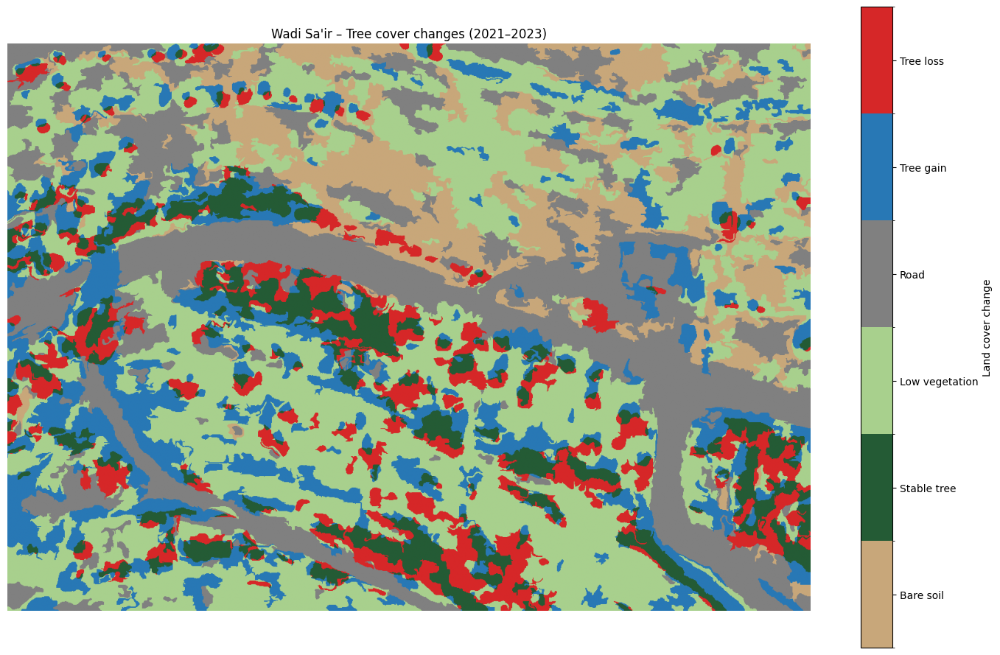

In [20]:
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.pyplot as plt
import numpy as np

# Start with the 2023 classification
change_map = data_2023_common.copy()

# Identify tree gains and losses
tree_gain = (data_2021_common != 2) & (data_2023_common == 2)
tree_loss = (data_2021_common == 2) & (data_2023_common != 2)

# Assign new values to highlight changes
change_map[tree_gain] = 5
change_map[tree_loss] = 6

# Define colours
colors = [
    "#C8A77A",  # 1 - Bare soil
    "#245B35",  # 2 - Stable tree
    "#A8D08D",  # 3 - Low vegetation
    "#808080",  # 4 - Road
    "#2878B5",  # 5 - Tree gain
    "#D62728"   # 6 - Tree loss
]

labels = [
    "Bare soil",
    "Stable tree",
    "Low vegetation",
    "Road",
    "Tree gain",
    "Tree loss"
]

cmap = ListedColormap(colors)
norm = BoundaryNorm(
    [0.5, 1.5, 2.5, 3.5, 4.5, 5.5, 6.5],
    cmap.N
)

# Plot
fig, ax = plt.subplots(figsize=(14, 9))

im = ax.imshow(change_map, cmap=cmap, norm=norm)

cbar = fig.colorbar(
    im,
    ax=ax,
    ticks=[1, 2, 3, 4, 5, 6],
    boundaries=[0.5, 1.5, 2.5, 3.5, 4.5, 5.5, 6.5]
)

cbar.ax.set_yticklabels(labels)
cbar.set_label("Land cover change")

ax.set_title("Wadi Sa'ir – Tree cover changes (2021–2023)")
ax.axis("off")

plt.tight_layout()
plt.show()

### 15. Exporting Tree Cover Changes for QGIS Visualisation

The detected tree gain and tree loss pixels are converted into vector polygons to facilitate further spatial analysis and visualisation.

Connected pixels belonging to the same change category are grouped into polygons using an 8-connectivity approach. For each polygon, the change type and its corresponding area are calculated and stored as attributes.

The resulting vector dataset is exported in **GeoPackage (`.gpkg`) format**, containing two categories:

- **Tree gain:** Areas where tree cover was detected in 2023 but not in 2021.
- **Tree loss:** Areas where tree cover was detected in 2021 but not in 2023.

The exported GeoPackage can then be loaded into QGIS to visualise the spatial distribution of tree cover changes and examine the extent of gains and losses across the study area.

In [21]:
import os
import numpy as np
import geopandas as gpd

from rasterio.features import shapes
from shapely.geometry import shape

# Prepare the two change masks
change_masks = {
    "Tree gain": tree_gain,
    "Tree loss": tree_loss
}

features = []

# Convert connected pixels into polygons
for change_type, mask in change_masks.items():

    polygons = shapes(
        mask.astype("uint8"),
        mask=mask,
        transform=transform_common,
        connectivity=8
    )

    for geometry, value in polygons:

        if value == 1:
            geom = shape(geometry)

            features.append({
                "change_type": change_type,
                "area_m2": geom.area,
                "area_ha": geom.area / 10000,
                "geometry": geom
            })

# Create GeoDataFrame
gdf_changes = gpd.GeoDataFrame(
    features,
    geometry="geometry",
    crs="EPSG:28191"
)

# Export to GeoPackage
output_path = "/content/Wadi_Sair_Tree_Changes_2021_2023.gpkg"

if os.path.exists(output_path):
    os.remove(output_path)

gdf_changes.to_file(
    output_path,
    layer="tree_changes",
    driver="GPKG"
)

print("Export completed!")
print("Number of polygons:", len(gdf_changes))
print("\nPolygons by category:")
print(gdf_changes["change_type"].value_counts())
print("\nTotal area by category (ha):")
print(gdf_changes.groupby("change_type")["area_ha"].sum())

NameError: name 'output_path' is not defined